# Chapitre 5 - Cours 2 : splines de lissage, degrés de liberté et choix de $\lambda$

Les splines de régression du cours 1 obligent à choisir le nombre et la position des
nœuds. Les **splines de lissage** contournent ce problème : on met un nœud en **chaque**
observation et l'on contrôle la complexité par une **pénalité** de courbure. Plan :

1. le critère pénalisé et sa solution (§5.4) ;
2. calcul matriciel en base de B-splines, données *bone* (figure 5.6) ;
3. matrice de lissage, degrés de liberté effectifs, forme de Reinsch et valeurs
   propres (§5.4.1, figures 5.7 et 5.8) ;
4. choix de $\lambda$ : compromis biais-variance et validation croisée (§5.5, figure 5.9) ;
5. régression logistique non paramétrique (§5.6).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (SmoothingSpline, bspline_basis, bspline_penalty_matrix,
                              natural_spline_basis, loocv_score, gcv_score)
set_style()

## 1. Le critère des splines de lissage

Parmi toutes les fonctions $f$ deux fois dérivables, on cherche celle qui minimise la
**somme des carrés résiduels pénalisée** (éq. (5.9) du livre)

$$
\mathrm{RSS}(f, \lambda) = \sum_{i=1}^{N}\{y_i - f(x_i)\}^2
  + \lambda \int \{f''(t)\}^2\,dt .
$$

Le premier terme mesure l'**attache aux données**, le second la **courbure** de $f$
($f''$ est nulle pour une droite). Le paramètre $\lambda \ge 0$ règle le compromis :

- $\lambda = 0$ : aucune pénalité, $f$ peut être n'importe quelle fonction interpolant
  les données ;
- $\lambda = \infty$ : aucune courbure tolérée, $f$ est la droite des moindres carrés.

**Théorème (exercice 5.7).** Le problème, posé sur un espace de fonctions de dimension
infinie, admet une solution **unique**, qui est une **spline cubique naturelle** dont les
nœuds sont les valeurs distinctes des $x_i$.

> **Intuition.** Fixons les valeurs $f(x_i) = z_i$. Le premier terme ne dépend plus que
> des $z_i$ ; il reste à minimiser $\int f''^2$ parmi les fonctions qui passent par les
> points $(x_i, z_i)$ : c'est la spline cubique naturelle interpolante qui réalise ce
> minimum (exercice 5.7). On peut donc se restreindre à cet espace de dimension $N$.

## 2. Forme matricielle

Écrivons $f(x) = \sum_{j} N_j(x)\theta_j$ dans une base de cet espace. Avec
$\{\mathbf N\}_{ij} = N_j(x_i)$ et $\{\Omega_N\}_{jk} = \int N_j''(t)N_k''(t)\,dt$, on a
$\int f''^2 = \theta^T\Omega_N\theta$ (par bilinéarité de l'intégrale), donc (éq. (5.11))

$$
\mathrm{RSS}(\theta, \lambda) = (\mathbf y - \mathbf N\theta)^T(\mathbf y - \mathbf N\theta)
  + \lambda\,\theta^T\Omega_N\theta .
$$

Le gradient en $\theta$ vaut $-2\mathbf N^T(\mathbf y - \mathbf N\theta) + 2\lambda\Omega_N\theta$ ;
l'annuler donne (éq. (5.12))

$$
\hat\theta = (\mathbf N^T\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf y ,
$$

une **régression ridge généralisée**. En pratique (annexe du chapitre, éq. (5.79)), on
travaille dans une base de **B-splines cubiques** : la pénalité impose d'elle-même la
linéarité aux bords, et les matrices sont creuses.

> **Remarque (implémentation).** La classe `SmoothingSpline` de `esl.ch05_splines` place
> les nœuds intérieurs aux valeurs distinctes $x_{(2)}, \dots, x_{(n-1)}$ et les nœuds de
> bord en $x_{(1)}$ et $x_{(n)}$ : c'est une base de $n + 2$ B-splines (exercice 5.8).
> La matrice $\Omega_B$ est calculée **exactement** : $B_j''$ est affine sur chaque
> intervalle entre nœuds, donc $B_j''B_k''$ est un polynôme de degré 2, intégré exactement
> par une quadrature de Gauss à 2 points.

Vérifions sur un exemple que $\gamma^T\Omega_B\gamma = \int f''^2$ pour
$f = \sum_j \gamma_j B_j$, en comparant à une intégration numérique fine.

In [2]:
rng = np.random.RandomState(0)
noeuds = np.sort(rng.uniform(0, 1, 8))
Om = bspline_penalty_matrix(noeuds, 0.0, 1.0)
gam = rng.randn(Om.shape[0])
tt = np.linspace(0, 1, 200001)
f2 = bspline_basis(tt, noeuds, 0.0, 1.0, deriv=2) @ gam
print("gamma^T Omega gamma  =", gam @ Om @ gam)
print("intégrale numérique  =", np.trapezoid(f2 ** 2, tt))

gamma^T Omega gamma  = 32731.739399694183
intégrale numérique  = 32731.739272045375


Le noyau de $\Omega_B$ (vecteurs $\gamma$ tels que $\gamma^T\Omega_B\gamma = 0$) correspond
aux fonctions de dérivée seconde nulle, c'est-à-dire aux **fonctions affines** : il est de
dimension 2.

In [3]:
vp = np.linalg.eigvalsh(Om)
print("plus petites valeurs propres de Omega :", np.round(vp[:4], 6) + 0.0)

plus petites valeurs propres de Omega : [  0.         0.        27.179188 211.390231]


## 3. Exemple : densité minérale osseuse (figure 5.6)

La réponse est la variation relative de la densité minérale osseuse (DMO) de la colonne
vertébrale chez des adolescents, mesurée entre deux visites, en fonction de l'âge. On
ajuste une spline de lissage séparément aux garçons et aux filles, avec **12 degrés de
liberté effectifs** (notion définie au §4 ci-dessous).

In [4]:
bone = datasets.load_bone()
print(bone.groupby("gender").agg(n=("age", "size"), ages_distincts=("age", "nunique"),
                                 age_min=("age", "min"), age_max=("age", "max")))

          n  ages_distincts  age_min  age_max
gender                                       
female  259             168      9.4    25.55
male    226             152      9.6    25.20


In [5]:
fits = {}
for g in ["male", "female"]:
    d = bone[bone["gender"] == g]
    fits[g] = SmoothingSpline(df=12).fit(d["age"].to_numpy(), d["spnbmd"].to_numpy())
    etendue = d["age"].max() - d["age"].min()
    print("%-6s : lambda = %.4f (échelle des âges), lambda/étendue^3 = %.6f, ddl = %.2f"
          % (g, fits[g].lam_, fits[g].lam_ / etendue ** 3, fits[g].df_))

male   : lambda = 0.8443 (échelle des âges), lambda/étendue^3 = 0.000222, ddl = 12.00
female : lambda = 1.0545 (échelle des âges), lambda/étendue^3 = 0.000250, ddl = 12.00


Le $\lambda$ dépend de l'échelle de $x$ : si l'on remplace $x$ par $x/s$, la dérivée
seconde est multipliée par $s^2$ et $dt$ par $1/s$, donc $\int f''^2$ est multiplié par
$s^3$. En ramenant les âges dans $[0, 1]$ (comme le fait le logiciel utilisé dans le
livre), on trouve $\lambda \approx 0{,}00022$ pour les garçons, la valeur annoncée dans
la légende de la figure 5.6.

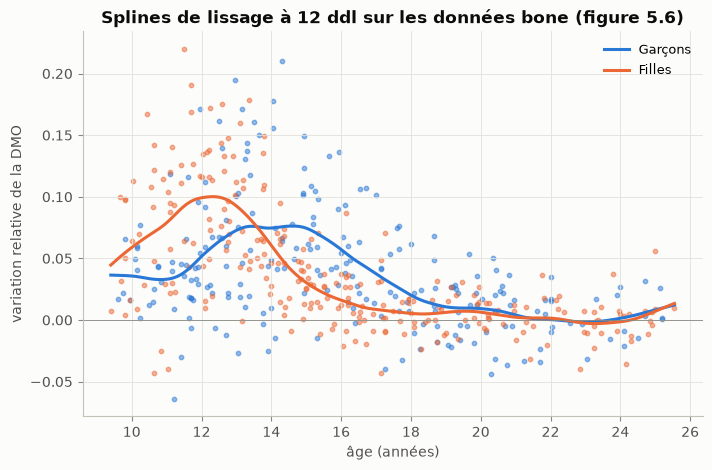

In [6]:
age_grid = np.linspace(bone["age"].min(), bone["age"].max(), 400)
noms = {"male": "Garçons", "female": "Filles"}
plt.figure(figsize=(8, 5))
for c, g in zip([BLUE, ORANGE], ["male", "female"]):
    d = bone[bone["gender"] == g]
    plt.scatter(d["age"], d["spnbmd"], s=10, color=c, alpha=0.5)
    plt.plot(age_grid, fits[g].predict(age_grid), color=c, lw=2.2, label=noms[g])
plt.axhline(0, color=GRAY, lw=0.6)
plt.xlabel("âge (années)")
plt.ylabel("variation relative de la DMO")
plt.title("Splines de lissage à 12 ddl sur les données bone (figure 5.6)")
plt.legend()
plt.show()

In [7]:
for g in ["male", "female"]:
    pic = age_grid[np.argmax(fits[g].predict(age_grid))]
    print("%-8s : pic de croissance osseuse vers %.1f ans" % (noms[g], pic))

Garçons  : pic de croissance osseuse vers 14.6 ans
Filles   : pic de croissance osseuse vers 12.3 ans


> **À retenir.** Ce résumé simple confirme que le pic de croissance des filles précède
> celui des garçons d'environ deux ans.

## 4. Matrice de lissage et degrés de liberté effectifs (§5.4.1)

Le vecteur des valeurs ajustées $\hat{\mathbf f} = (\hat f(x_i))_i$ s'écrit (éq. (5.14))

$$
\hat{\mathbf f} = \mathbf N(\mathbf N^T\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf y
  = \mathbf S_\lambda\,\mathbf y .
$$

C'est un **lisseur linéaire** : $\mathbf S_\lambda$ (la *matrice de lissage*) ne dépend que
des $x_i$ et de $\lambda$, pas de $\mathbf y$. Comparons-la à la matrice de projection
d'une spline de régression à $M$ fonctions de base (éq. (5.15)) :
$\mathbf H_\xi = \mathbf B_\xi(\mathbf B_\xi^T\mathbf B_\xi)^{-1}\mathbf B_\xi^T$.

- Les deux sont **symétriques semi-définies positives**.
- $\mathbf H_\xi^2 = \mathbf H_\xi$ (projection) tandis que
  $\mathbf S_\lambda^2 \preceq \mathbf S_\lambda$ : la différence
  $\mathbf S_\lambda - \mathbf S_\lambda^2$ est semi-définie positive (*rétrécissement*).
- $\mathbf H_\xi$ est de rang $M$, $\mathbf S_\lambda$ de rang $N$.

Pour étudier $\mathbf S_\lambda$, prenons les filles en gardant **une seule observation
par âge** : les $x_i$ sont alors distincts et $\mathbf S_\lambda$ est inversible.

In [8]:
fem = bone[bone["gender"] == "female"].drop_duplicates("age").sort_values("age")
xf, yf = fem["age"].to_numpy(), fem["spnbmd"].to_numpy()
Nf = len(xf)
ss12 = SmoothingSpline(df=12).fit(xf, yf)
S = ss12.smoother_matrix()
kn = np.quantile(xf, np.linspace(0, 1, 10))[1:-1]          # 8 nœuds -> 12 fonctions
Bx = bspline_basis(xf, kn, xf.min(), xf.max())
Hx = Bx @ np.linalg.solve(Bx.T @ Bx, Bx.T)
print("N =", Nf, " | trace(S) = %.2f, trace(H) = %.2f" % (np.trace(S), np.trace(Hx)))

N = 168  | trace(S) = 12.00, trace(H) = 12.00


In [9]:
def resume(M, nom):
    vp = np.linalg.eigvalsh(M)
    vp2 = np.linalg.eigvalsh(M - M @ M)
    print("%s : sym. %s | vp dans [%.2e, %.4f] | rang %d | min vp(M - M^2) = %.1e"
          % (nom, np.allclose(M, M.T), vp.min(), vp.max(),
             np.linalg.matrix_rank(M, tol=1e-10), vp2.min()))

resume(S, "S_lambda")
resume(Hx, "H_xi    ")
print("||H^2 - H|| =", np.abs(Hx @ Hx - Hx).max())

S_lambda : sym. True | vp dans [4.15e-06, 1.0000] | rang 168 | min vp(M - M^2) = -6.8e-16
H_xi     : sym. True | vp dans [-6.94e-16, 1.0000] | rang 12 | min vp(M - M^2) = -1.1e-15
||H^2 - H|| = 4.996003610813204e-16


### Degrés de liberté effectifs

Pour la projection, $\mathrm{tr}(\mathbf H_\xi) = M$ est le nombre de paramètres. Par
analogie, on définit les **degrés de liberté effectifs** d'une spline de lissage par
(éq. (5.16))

$$
\mathrm{df}_\lambda = \mathrm{tr}(\mathbf S_\lambda) .
$$

C'est une fonction **strictement décroissante** de $\lambda$, de $N$ (interpolation)
à 2 (droite). On peut donc spécifier la quantité de lissage par $\mathrm{df}_\lambda$,
plus parlant que $\lambda$, puis retrouver $\lambda$ numériquement (§5.5.1).

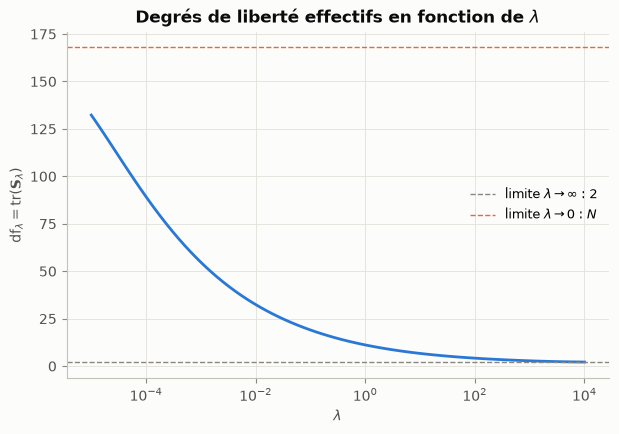

In [10]:
lams = np.logspace(-5, 4, 80)
dfs = [SmoothingSpline(lam=l).fit(xf, yf).df_ for l in lams]
plt.figure(figsize=(7, 4.5))
plt.semilogx(lams, dfs, color=BLUE)
plt.axhline(2, color=GRAY, ls="--", lw=1, label="limite $\\lambda\\to\\infty$ : 2")
plt.axhline(Nf, color=ORANGE, ls="--", lw=1, label="limite $\\lambda\\to 0$ : $N$")
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\mathrm{df}_\lambda = \mathrm{tr}(\mathbf{S}_\lambda)$")
plt.title("Degrés de liberté effectifs en fonction de $\\lambda$")
plt.legend()
plt.show()

### Forme de Reinsch et décomposition spectrale

Comme $\mathbf N$ est carrée inversible (base de dimension $N$),
$\mathbf S_\lambda = \mathbf N(\mathbf N^T\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T
= \big(\mathbf N^{-T}(\mathbf N^T\mathbf N + \lambda\Omega_N)\mathbf N^{-1}\big)^{-1}$,
d'où la **forme de Reinsch** (éq. (5.17), exercice 5.9)

$$
\mathbf S_\lambda = (\mathbf I + \lambda\mathbf K)^{-1},\qquad
\mathbf K = \mathbf N^{-T}\Omega_N\mathbf N^{-1} .
$$

$\hat{\mathbf f}$ minimise alors $(\mathbf y - \mathbf f)^T(\mathbf y - \mathbf f)
+ \lambda\mathbf f^T\mathbf K\mathbf f$ (éq. (5.18)) : $\mathbf K$ est la **matrice de
pénalité**, indépendante de $\lambda$. Si $\mathbf K = \sum_k d_k\mathbf u_k\mathbf u_k^T$
(symétrique réelle, donc diagonalisable en base orthonormée), alors (éq. (5.19)-(5.20))

$$
\mathbf S_\lambda = \sum_{k=1}^{N}\rho_k(\lambda)\,\mathbf u_k\mathbf u_k^T,\qquad
\rho_k(\lambda) = \frac{1}{1 + \lambda d_k} .
$$

Vérifions numériquement que les vecteurs propres ne dépendent pas de $\lambda$ et que
$d_k = (1/\rho_k - 1)/\lambda$ est le même pour deux valeurs de $\lambda$
(correspondant à 5 et 11 ddl, comme dans la figure 5.7).

In [11]:
ss5 = SmoothingSpline(df=5).fit(xf, yf)
ss11 = SmoothingSpline(df=11).fit(xf, yf)
rho5, U5 = np.linalg.eigh(ss5.smoother_matrix())
rho11, U11 = np.linalg.eigh(ss11.smoother_matrix())
rho5, U5, rho11, U11 = rho5[::-1], U5[:, ::-1], rho11[::-1], U11[:, ::-1]
k = np.arange(2, 8)
print("d_k (df=5)  :", np.round((1 / rho5[k] - 1) / ss5.lam_, 4))
print("d_k (df=11) :", np.round((1 / rho11[k] - 1) / ss11.lam_, 4))
print("|<u_k(5), u_k(11)>| pour k = 1..8 :", np.round(np.abs(np.sum(U5[:, :8] * U11[:, :8], 0)), 6))

d_k (df=5)  : [0.0008 0.0058 0.023  0.0596 0.14   0.2589]
d_k (df=11) : [0.0008 0.0058 0.023  0.0596 0.14   0.2589]
|<u_k(5), u_k(11)>| pour k = 1..8 : [1. 1. 1. 1. 1. 1. 1. 1.]


Reproduisons la figure 5.7 sur ces données : en haut les deux ajustements ; en bas à
gauche les 25 premières valeurs propres $\rho_k(\lambda)$ ; en bas à droite les vecteurs
propres $\mathbf u_3, \dots, \mathbf u_6$ (tracés comme fonctions de $x$) et leurs
versions rétrécies $\rho_k\mathbf u_k$ par le lisseur à 5 ddl.

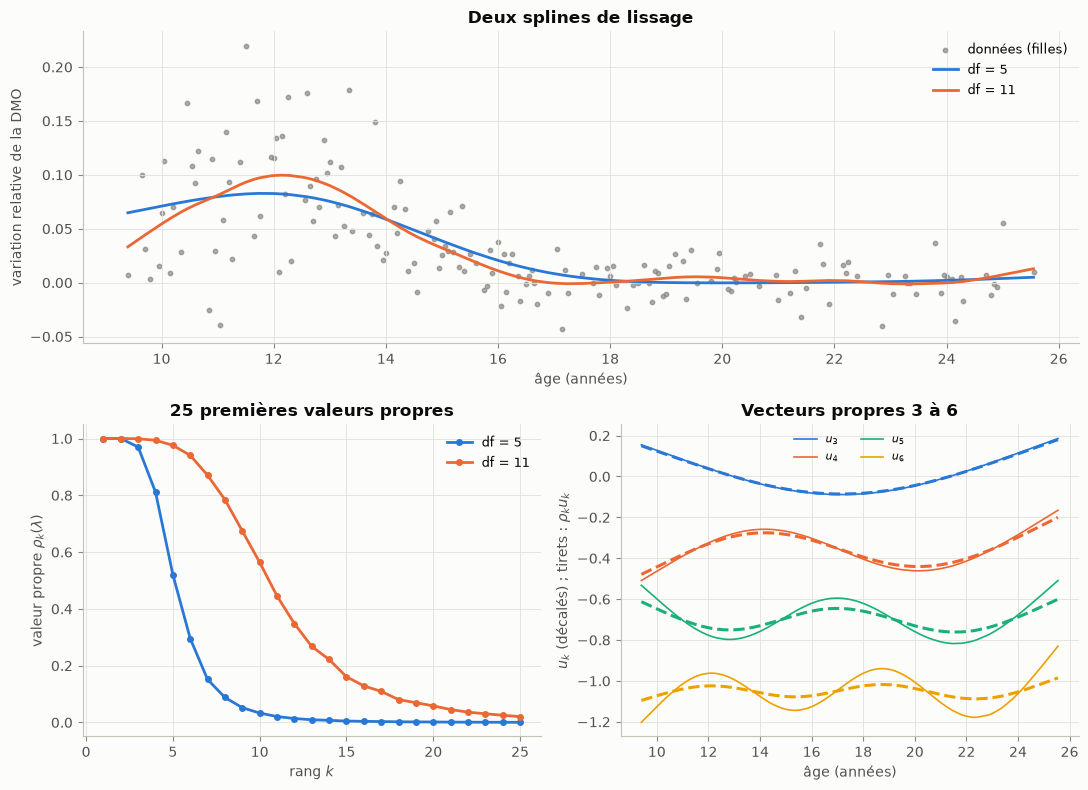

In [12]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(2, 1, 1)
ax.scatter(xf, yf, s=10, color=GRAY, alpha=0.7, label="données (filles)")
ax.plot(xf, ss5.smoother_matrix() @ yf, color=BLUE, label="df = 5")
ax.plot(xf, ss11.smoother_matrix() @ yf, color=ORANGE, label="df = 11")
ax.set_xlabel("âge (années)")
ax.set_ylabel("variation relative de la DMO")
ax.set_title("Deux splines de lissage")
ax.legend()
ax = fig.add_subplot(2, 2, 3)
ax.plot(np.arange(1, 26), rho5[:25], "o-", color=BLUE, ms=4, label="df = 5")
ax.plot(np.arange(1, 26), rho11[:25], "o-", color=ORANGE, ms=4, label="df = 11")
ax.set_xlabel("rang $k$")
ax.set_ylabel(r"valeur propre $\rho_k(\lambda)$")
ax.set_title("25 premières valeurs propres")
ax.legend()
ax = fig.add_subplot(2, 2, 4)
for j, kk in enumerate(range(2, 6)):
    u = U5[:, kk] * np.sign(U5[np.argmax(np.abs(U5[:, kk])), kk])
    off = -0.35 * j
    ax.plot(xf, u + off, color=COLORS[j], lw=1.2, label="$u_{%d}$" % (kk + 1))
    ax.plot(xf, rho5[kk] * u + off, color=COLORS[j], lw=2.2, ls="--")
ax.set_xlabel("âge (années)")
ax.set_ylabel("$u_k$ (décalés) ; tirets : $\\rho_k u_k$")
ax.set_title("Vecteurs propres 3 à 6")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

Points saillants de la représentation spectrale :

- les **vecteurs propres ne dépendent pas de $\lambda$** : toute la famille de splines de
  lissage (pour des $x_i$ donnés) partage la même base $\{\mathbf u_k\}$ ;
- $\mathbf S_\lambda\mathbf y = \sum_k \mathbf u_k\,\rho_k(\lambda)\langle\mathbf u_k,
  \mathbf y\rangle$ : la spline **décompose** $\mathbf y$ sur la base $\{\mathbf u_k\}$ et
  **rétrécit différemment** chaque composante ; une projection, au contraire, garde
  ($\rho = 1$) ou annule ($\rho = 0$) les composantes ;
- les $\mathbf u_k$ ressemblent à des polynômes de plus en plus oscillants quand $k$
  croît ;
- $\rho_1 = \rho_2 = 1$ : les fonctions affines ($d_1 = d_2 = 0$) ne sont **jamais**
  rétrécies ;
- $\mathrm{df}_\lambda = \mathrm{tr}(\mathbf S_\lambda) = \sum_k\rho_k(\lambda)$.

In [13]:
print("somme des rho_k (df=5)  :", rho5.sum())
print("somme des rho_k (df=11) :", rho11.sum())

somme des rho_k (df=5)  : 4.999999999999995
somme des rho_k (df=11) : 11.000000000000004


Dans la base des vecteurs propres, avec $\mathbf y = \mathbf U\theta$, le problème devient
(éq. (5.21)) $\min_\theta \|\mathbf y - \mathbf U\theta\|^2 + \lambda\theta^T\mathbf D\theta$
avec $\mathbf D = \mathrm{diag}(d_k)$ : une régression ridge **diagonale**, où
chaque coordonnée est pénalisée proportionnellement à sa « rugosité » $d_k$.

### Noyaux équivalents (figure 5.8)

La ligne $i$ de $\mathbf S_\lambda$ donne les poids avec lesquels $\hat f(x_i)$ combine
les $y_j$ : c'est le **noyau équivalent** au point $x_i$. La matrice est presque
**diagonale par bandes** : le lissage est local, comme pour les méthodes à noyau du
chapitre 6.

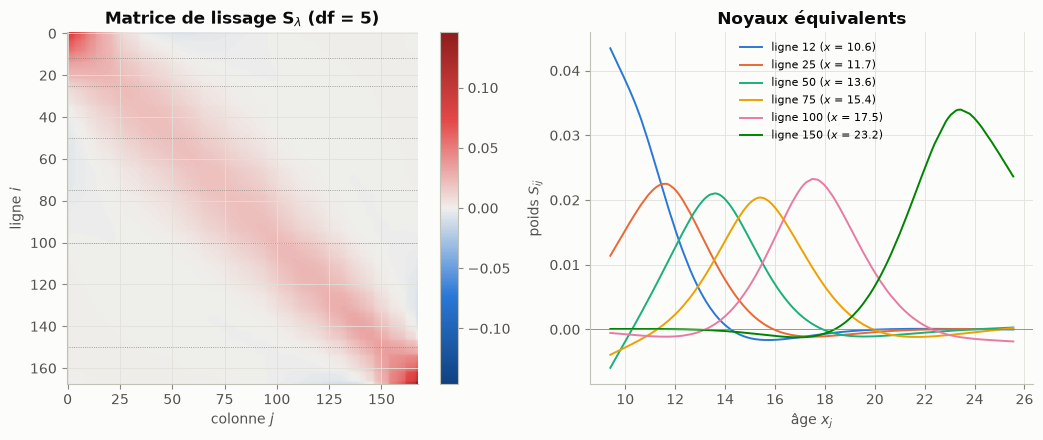

In [14]:
S5 = ss5.smoother_matrix()
lignes = [12, 25, 50, 75, 100, 150]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].imshow(S5, cmap=DIV, vmin=-np.abs(S5).max(), vmax=np.abs(S5).max())
for l in lignes:
    axes[0].axhline(l, color=GRAY, lw=0.6, ls=":")
axes[0].set_title("Matrice de lissage $\\mathbf{S}_\\lambda$ (df = 5)")
axes[0].set_xlabel("colonne $j$")
axes[0].set_ylabel("ligne $i$")
fig.colorbar(im, ax=axes[0], fraction=0.046)
for c, l in zip(COLORS, lignes):
    axes[1].plot(xf, S5[l], color=c, lw=1.4, label="ligne %d ($x$ = %.1f)" % (l, xf[l]))
axes[1].axhline(0, color=GRAY, lw=0.6)
axes[1].set_xlabel("âge $x_j$")
axes[1].set_ylabel("poids $S_{ij}$")
axes[1].set_title("Noyaux équivalents")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

> **Remarque.** Près des bords, le noyau équivalent devient **asymétrique** (et prend
> des valeurs négatives) : la spline extrapole linéairement l'information intérieure.

## 5. Choix automatique de $\lambda$ (§5.5)

### Compromis biais-variance

Simulons le modèle (éq. (5.22))

$$
Y = f(X) + \varepsilon,\qquad f(X) = \frac{\sin(12(X + 0{,}2))}{X + 0{,}2},
\qquad X \sim \mathcal U[0,1],\ \varepsilon \sim \mathcal N(0, 1),
$$

avec $N = 100$. Comme $\hat{\mathbf f} = \mathbf S_\lambda\mathbf y$ et
$\mathrm{Cov}(\mathbf y) = \sigma^2\mathbf I$ (avec $\sigma = 1$), on a (éq. (5.23)-(5.24))

$$
\mathrm{Cov}(\hat{\mathbf f}) = \mathbf S_\lambda\mathbf S_\lambda^T,\qquad
\mathrm{Biais}(\hat{\mathbf f}) = \mathbf f - \mathbb E\hat{\mathbf f}
  = \mathbf f - \mathbf S_\lambda\mathbf f .
$$

In [15]:
rng = np.random.RandomState(0)
Ns = 100
xs = np.sort(rng.uniform(0, 1, Ns))
fsim = lambda t: np.sin(12 * (t + 0.2)) / (t + 0.2)
ys = fsim(xs) + rng.randn(Ns)
fx = fsim(xs)

L'erreur de prédiction intégrée combine biais et variance (éq. (5.25)) :

$$
\mathrm{EPE}(\hat f_\lambda) = \mathbb E(Y - \hat f_\lambda(X))^2
  = \sigma^2 + \mathbb E\big[\mathrm{Biais}^2(\hat f_\lambda(X)) +
    \mathrm{Var}(\hat f_\lambda(X))\big] .
$$

Nous l'évaluons en moyennant sur les $x_i$ d'apprentissage :
$\mathrm{EPE} \approx \sigma^2 + \frac1N\big(\|\mathbf f - \mathbf S_\lambda\mathbf f\|^2
+ \sigma^2\,\mathrm{tr}(\mathbf S_\lambda\mathbf S_\lambda^T)\big)$, et nous la comparons
à la validation croisée.

### Validation croisée « leave-one-out »

Le critère (éq. (5.26)) $\mathrm{CV}(\hat f_\lambda) = \frac1N\sum_i (y_i - \hat
f_\lambda^{(-i)}(x_i))^2$, où $\hat f^{(-i)}$ est ajustée sans l'observation $i$, se calcule
**sans réajuster** grâce à la formule (éq. (5.27), exercice 5.13)

$$
\mathrm{CV}(\hat f_\lambda) = \frac1N\sum_{i=1}^{N}
  \left(\frac{y_i - \hat f_\lambda(x_i)}{1 - S_\lambda(i,i)}\right)^2 .
$$

Vérifions-la par force brute pour une valeur de $\lambda$.

In [16]:
lam9 = SmoothingSpline(df=9).fit(xs, ys).lam_
err = []
for i in range(Ns):
    m = np.arange(Ns) != i
    err.append(ys[i] - SmoothingSpline(lam=lam9).fit(xs[m], ys[m]).predict(xs[i:i + 1])[0])
print("CV par force brute : %.6f" % np.mean(np.square(err)))
print("CV par (5.27)      : %.6f" % loocv_score(xs, ys, lam9))

CV par force brute : 1.087807
CV par (5.27)      : 1.087807


In [17]:
df_grid = np.linspace(5, 15, 41)
epe, cv, gcv = [], [], []
for dfv in df_grid:
    s = SmoothingSpline(df=dfv).fit(xs, ys)
    Sm = s.smoother_matrix()
    epe.append(1 + (np.sum((fx - Sm @ fx) ** 2) + np.trace(Sm @ Sm.T)) / Ns)
    cv.append(loocv_score(xs, ys, s.lam_))
    gcv.append(gcv_score(xs, ys, s.lam_))
print("df minimisant EPE : %.2f ; CV : %.2f ; GCV : %.2f"
      % (df_grid[np.argmin(epe)], df_grid[np.argmin(cv)], df_grid[np.argmin(gcv)]))

df minimisant EPE : 9.50 ; CV : 9.25 ; GCV : 9.25


La figure 5.9 : en haut à gauche, les courbes EPE et CV ; puis trois ajustements avec la
bande $\hat f_\lambda(x) \pm 2\,\mathrm{se}(\hat f_\lambda(x))$, où
$\mathrm{se}^2 = \mathrm{diag}(\mathbf S_\lambda\mathbf S_\lambda^T)$.

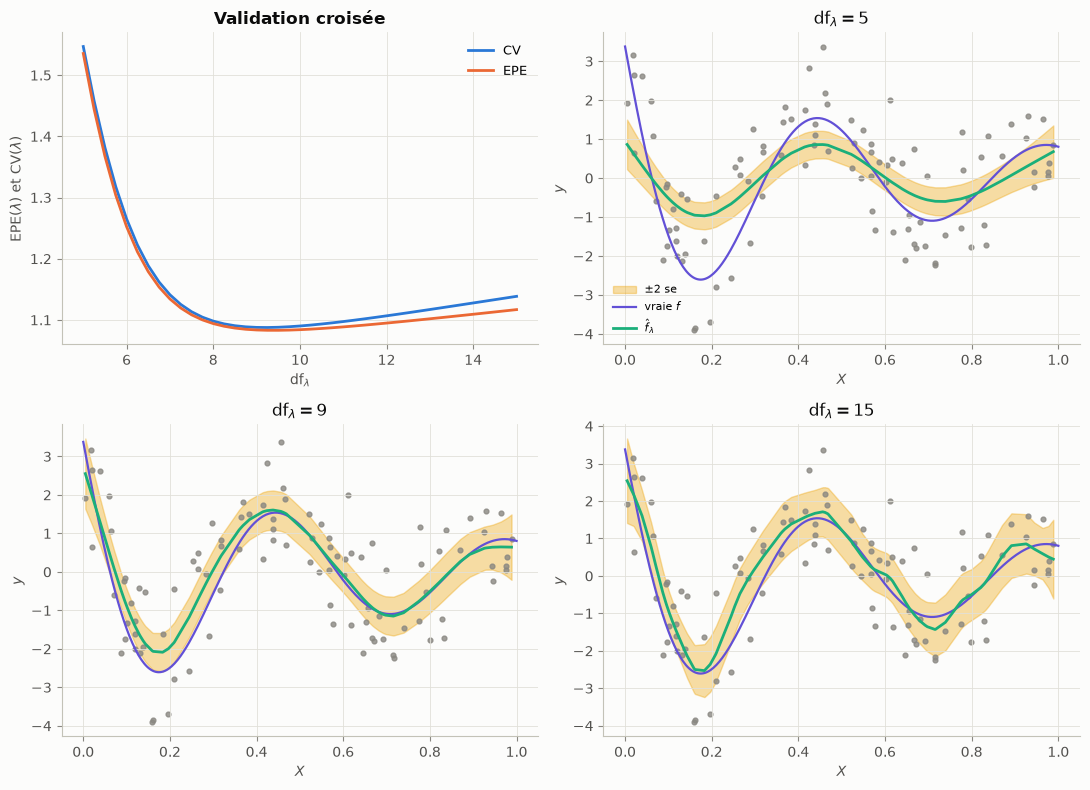

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax = axes[0, 0]
ax.plot(df_grid, cv, color=BLUE, label="CV")
ax.plot(df_grid, epe, color=ORANGE, label="EPE")
ax.set_xlabel(r"$\mathrm{df}_\lambda$")
ax.set_ylabel(r"EPE($\lambda$) et CV($\lambda$)")
ax.set_title("Validation croisée")
ax.legend()
gx = np.linspace(0, 1, 300)
for ax, dfv in zip([axes[0, 1], axes[1, 0], axes[1, 1]], [5, 9, 15]):
    s = SmoothingSpline(df=dfv).fit(xs, ys)
    Sm = s.smoother_matrix()
    se = np.sqrt(np.diag(Sm @ Sm.T))
    fit = Sm @ ys
    ax.fill_between(xs, fit - 2 * se, fit + 2 * se, color=COLORS[3], alpha=0.35,
                    label=r"$\pm 2$ se")
    ax.scatter(xs, ys, s=12, color=GRAY, alpha=0.8)
    ax.plot(gx, fsim(gx), color=COLORS[6], lw=1.6, label="vraie $f$")
    ax.plot(xs, fit, color=COLORS[2], lw=2, label=r"$\hat f_\lambda$")
    ax.set_title(r"$\mathrm{df}_\lambda = %d$" % dfv)
    ax.set_xlabel("$X$")
    ax.set_ylabel("$y$")
axes[0, 1].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

Lecture de la figure :

- **df = 5** : la spline sous-ajuste, rabote les sommets et comble les creux ; biais
  important là où la courbure est forte, bande étroite : on estime avec beaucoup de
  précision une version **biaisée** de $f$ ;
- **df = 9** : l'ajustement est proche de la vraie fonction, la variance n'a presque pas
  augmenté ;
- **df = 15** : la courbe ondule davantage et la bande s'élargit : la spline commence à
  suivre certains points de trop près.

Les courbes EPE et CV ont la même allure et un minimum proche : la CV, calculable sans
connaître $f$, est un bon substitut. L'exercice 5.10 complète cette étude en montrant le
biais et des quantiles de $\hat f_\lambda(x)$.

> **Remarque (GCV).** La validation croisée généralisée remplace chaque $S_\lambda(i,i)$
> par leur moyenne $\mathrm{df}_\lambda/N$ :
> $\mathrm{GCV}(\lambda) = \frac1N\sum_i\big(\frac{y_i - \hat f_\lambda(x_i)}{1 -
> \mathrm{df}_\lambda/N}\big)^2$. Elle est souvent plus stable numériquement (chapitre 7).

Appliquons la CV aux données *bone* (filles, une observation par âge) pour choisir les
degrés de liberté.

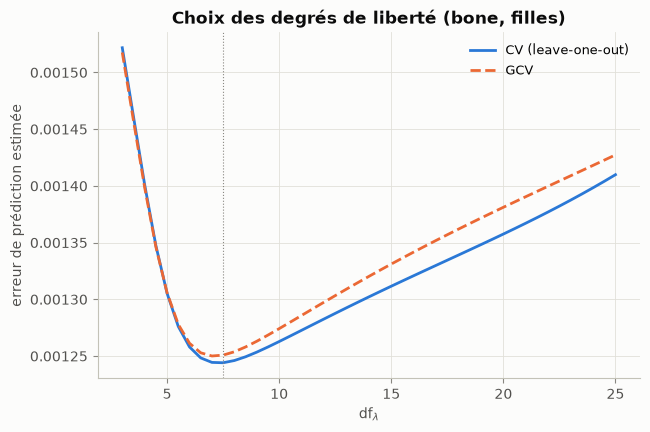

df choisi par CV : 7.5


In [19]:
df_b = np.linspace(3, 25, 45)
cv_b = [loocv_score(xf, yf, SmoothingSpline(df=v).fit(xf, yf).lam_) for v in df_b]
gcv_b = [gcv_score(xf, yf, SmoothingSpline(df=v).fit(xf, yf).lam_) for v in df_b]
plt.figure(figsize=(7, 4.5))
plt.plot(df_b, cv_b, color=BLUE, label="CV (leave-one-out)")
plt.plot(df_b, gcv_b, color=ORANGE, ls="--", label="GCV")
plt.axvline(df_b[np.argmin(cv_b)], color=GRAY, lw=0.8, ls=":")
plt.xlabel(r"$\mathrm{df}_\lambda$")
plt.ylabel("erreur de prédiction estimée")
plt.title("Choix des degrés de liberté (bone, filles)")
plt.legend()
plt.show()
print("df choisi par CV : %.1f" % df_b[np.argmin(cv_b)])

## 6. Régression logistique non paramétrique (§5.6)

Pour une réponse binaire, on modélise $\log\frac{\Pr(Y=1\mid x)}{\Pr(Y=0\mid x)} = f(x)$
et l'on maximise la log-vraisemblance pénalisée (éq. (5.30))

$$
\ell(f; \lambda) = \sum_{i=1}^{N}\big[y_i f(x_i) - \log(1 + e^{f(x_i)})\big]
  - \frac{\lambda}{2}\int\{f''(t)\}^2\,dt .
$$

La solution est encore une spline naturelle à nœuds aux $x_i$. L'algorithme de
Newton-Raphson (comme l'IRLS du chapitre 4) donne la mise à jour (éq. (5.33)-(5.34))

$$
\mathbf f^{\text{new}} = \mathbf S_{\lambda, w}\,\mathbf z,\qquad
\mathbf z = \mathbf f^{\text{old}} + \mathbf W^{-1}(\mathbf y - \mathbf p),\qquad
\mathbf W = \mathrm{diag}(p_i(1 - p_i)),
$$

c'est-à-dire une **spline de lissage pondérée** de la réponse de travail $\mathbf z$.
Illustration : risque de maladie coronarienne en fonction de l'âge (données *SAheart*).

In [20]:
sa = datasets.load_saheart()
xa, ya = sa["age"].to_numpy(float), sa["chd"].to_numpy(float)
lam_a = 500.0
f = np.zeros_like(xa)
for it in range(30):
    p = 1 / (1 + np.exp(-f))
    w = p * (1 - p)
    z = f + (ya - p) / w
    s = SmoothingSpline(lam=lam_a).fit(xa, z, w=w)
    f_new = s.predict(xa)
    if np.max(np.abs(f_new - f)) < 1e-8:
        break
    f = f_new
print("convergence en %d itérations, ddl effectifs = %.2f" % (it + 1, s.df_))

convergence en 7 itérations, ddl effectifs = 5.08


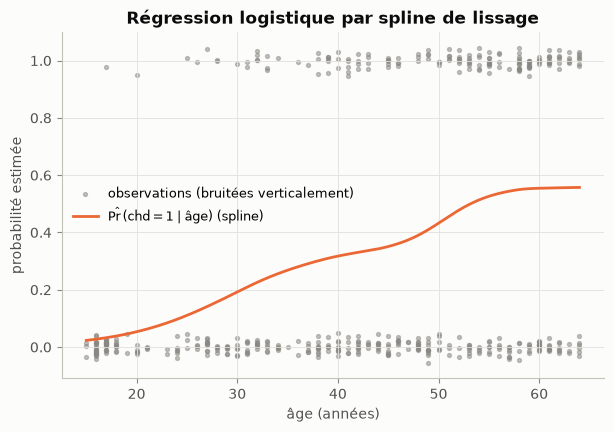

In [21]:
ga = np.linspace(xa.min(), xa.max(), 300)
pa = 1 / (1 + np.exp(-s.predict(ga)))
plt.figure(figsize=(7, 4.5))
plt.scatter(xa, ya + 0.02 * np.random.RandomState(0).randn(len(ya)), s=8, color=GRAY,
            alpha=0.5, label="observations (bruitées verticalement)")
plt.plot(ga, pa, color=ORANGE, label=r"$\hat{\Pr}(\mathrm{chd}=1\mid \mathrm{âge})$ (spline)")
plt.xlabel("âge (années)")
plt.ylabel("probabilité estimée")
plt.title("Régression logistique par spline de lissage")
plt.legend()
plt.show()

> **À retenir.**
> - La spline de lissage minimise $\sum(y_i - f(x_i))^2 + \lambda\int f''^2$ ; la
>   solution est une spline cubique naturelle à nœuds aux $x_i$, obtenue par une
>   régression ridge généralisée.
> - $\hat{\mathbf f} = \mathbf S_\lambda\mathbf y$ avec
>   $\mathbf S_\lambda = (\mathbf I + \lambda\mathbf K)^{-1}$ ; ses valeurs propres
>   $\rho_k = 1/(1 + \lambda d_k)$ rétrécissent les composantes rugueuses.
> - $\mathrm{df}_\lambda = \mathrm{tr}(\mathbf S_\lambda)$ paramètre la complexité de
>   façon parlante.
> - $\lambda$ se choisit par CV, calculable en une seule passe grâce à (5.27).